In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
def atol(a, b):
    return torch.abs(a.to(torch.float64) - b.to(torch.float64)).max().item()

In [3]:
def load_fwd(single_file, multi_path):
    single = torch.load(single_file)
    m0 = torch.load(multi_path + '/rank0.pt')
    m4 = torch.load(multi_path + '/rank4.pt')
    distr = m0 + m4
    single_idx = {n: i for (i, (n, _)) in enumerate(single) if n.startswith('batch_0.')}

    s = {}
    d = {}
    for (n, t) in distr:
        if n in single_idx:
            s[n] = single[single_idx[n]][1]
            d[n] = t

    return s, d, single, distr

In [4]:
s, d, _, _ = load_fwd('24-06-26-16-03-single-fp16.pt', '24-06-26-16-03-fp16')
diff = {n: atol(d[n], s[n]) for n in s}

In [6]:
s_bf16, d_bf16, _, _ = load_fwd('24-07-08-12-58-single.pt', '24-07-08-11-58')
diff_bf16 = {n: atol(d_bf16[n], s_bf16[n]) for n in s_bf16}

In [12]:
s_32, d_32, _, _ = load_fwd('24-07-08-14-17-single-fp32.pt', '24-07-08-14-22-fp32')
diff_32 = {n: atol(d_32[n], s_32[n]) for n in s_32}

In [24]:
diff_bf = {n: atol(d_bf16[n], s_32[n]) for n in s_32}
diff_fp = {n: atol(d[n], s_32[n]) for n in s_32}

In [32]:
siff_bf = {n: atol(s_bf16[n], s_32[n]) for n in s_32}
siff_fp = {n: atol(s[n], s_32[n]) for n in s_32}

Text(0, 0.5, 'Max abs diff')

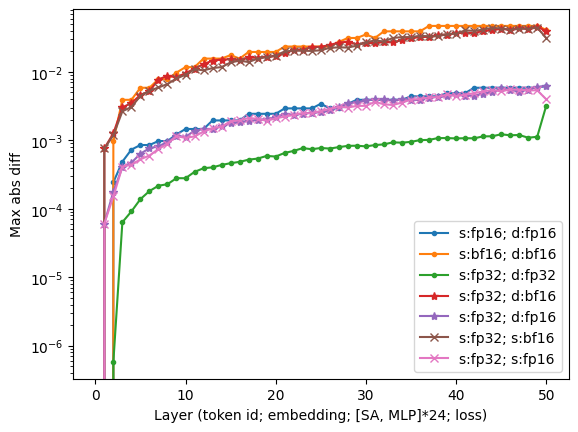

In [37]:
plt.plot(range(len(diff)), diff.values(), '.-')
plt.plot(range(len(diff_bf16)), diff_bf16.values(), '.-')
plt.plot(range(len(diff_32)), diff_32.values(), '.-')
plt.plot(range(len(diff_bf)), diff_bf.values(), '*-')
plt.plot(range(len(diff_fp)), diff_fp.values(), '*-')
plt.plot(range(len(siff_bf)), siff_bf.values(), 'x-')
plt.plot(range(len(siff_fp)), siff_fp.values(), 'x-')
plt.yscale('log')
plt.legend(['s:fp16; d:fp16', 's:bf16; d:bf16', 's:fp32; d:fp32', 's:fp32; d:bf16', 's:fp32; d:fp16', 's:fp32; s:bf16', 's:fp32; s:fp16'])
plt.xlabel('Layer (token id; embedding; [SA, MLP]*24; loss)')
plt.ylabel('Max abs diff')

In [23]:
s, b, _, _ = load_fwd('24-06-26-16-03-single.pt', '24-06-26-16-30-buggy')

In [29]:
biff = {n: atol(b[n], s[n]) for n in s}

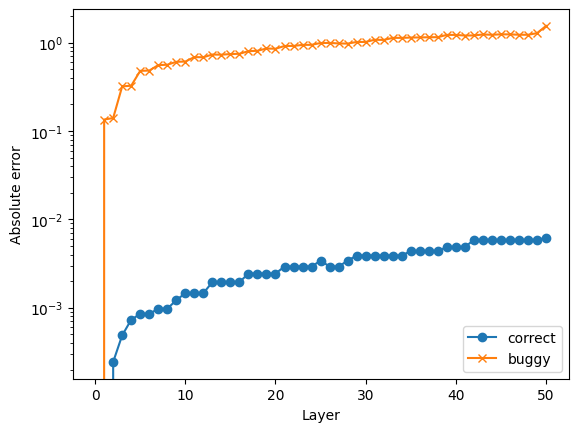

In [35]:
plt.plot(range(len(diff)), diff.values(), 'o-')
plt.plot(range(len(biff)), biff.values(), 'x-')
plt.yscale('log')
plt.legend(['correct', 'buggy'])
plt.xlabel('Layer')
plt.ylabel('Absolute error')
plt.show()

In [5]:
s, d, _, _ = load_fwd('single-fp32.pt', 'bf16')
_, b, _, _ = load_fwd('single-fp32.pt', 'bf16-bug')

FileNotFoundError: [Errno 2] No such file or directory: 'bf16-bug/rank0.pt'